123
median_size 1088.0
82 2
d_typical 250.0


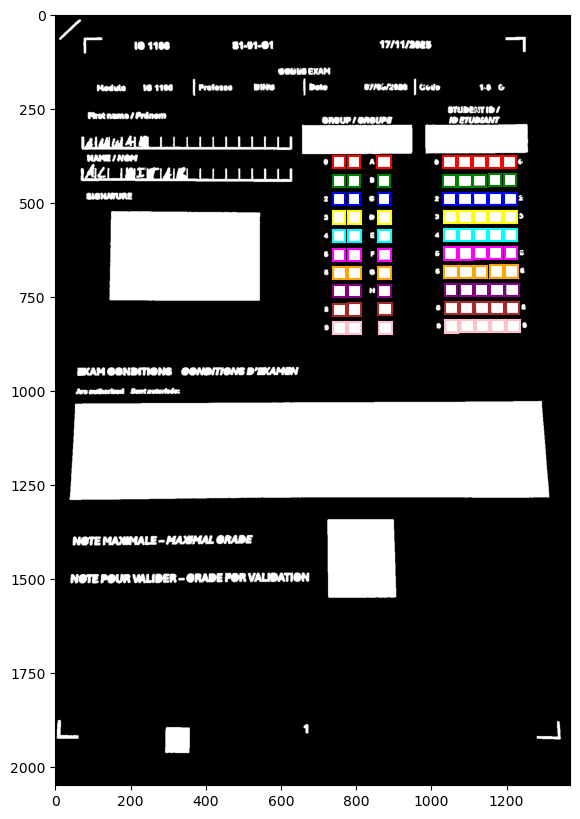

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy.optimize as sp
import skimage.io as ski 
import os
from skimage import color
from skimage import filters
from skimage import feature
from skimage.transform import hough_line, hough_line_peaks, rotate
from skimage import feature, morphology
from scipy.ndimage import binary_fill_holes
import skimage
from scipy import ndimage
# import skimage.io as ski
# im = ski.imread("FORM1/EXAM_FORM1_62445.jpg") # traitement contratste
# im = ski.imread("FORM1\EXAM_FORM1_61856.jpg")
# im = ski.imread("FORM1\EXAM_FORM1_62401.jpg") # image de reférence
# im = ski.imread("FORM1\EXAM_FORM1_54331.jpg") # 2 image 
# im = ski.imread("FORM1\EXAM_FORM1_54331.jpg")# illisible faux
# im = ski.imread("FORM1\EXAM_FORM1_63807.jpeg")# illisible
# im = ski.imread("FORM1\EXAM_FORM1_58220.jpg")


# im = ski.imread("FORM1\EXAM_FORM1_50305.jpg")
# im = ski.imread("FORM1\EXAM_FORM1_19283.jpeg")
im = ski.imread("FORM1\EXAM_FORM1_62440.jpeg")

# im = ski.imread("FORM1\EXAM_FORM1_62380.jpeg")

if im.shape[1]>im.shape[0]:
    im = rotate(im, -90)
im_rgb = im[:, :, :3]  # on garde uniquement R, G, B
im2 = color.rgb2gray(im_rgb)

# dir(skimage.filters)
im3 = filters.sobel(im2)


size = 2
seuil = filters.threshold_otsu(im3)
im4 = im3>seuil*0.7
im35=im4.copy()
im4 = morphology.remove_small_objects(im4, min_size=100)
# im_dilate = ndimage.binary_dilation(im4, structure=np.ones((size, size)))
# im_close = morphology.binary_closing(im_dilate, morphology.square(size))
# im4 = binary_fill_holes(im_close)
im4 = binary_fill_holes(im4)
imlabel, nbCC   = skimage.measure.label(im4, connectivity=2, return_num= True)
regionprops= skimage.measure.regionprops(imlabel)

# --- 1. Filtrage initial (densité + forme) ---

dimMax = []

for k in range(len(regionprops)):

    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    pattern = imlabel[min_row:max_row, min_col:max_col] > 0
    
    dimL, diml = pattern.shape
    size = dimL * diml
    nbones = np.sum(pattern)
    density = nbones / size
    
    ratio = dimL / diml
    
    perimeter = regionprops[k].perimeter
    compactness = size / (perimeter ** 2)


    if density > 0.6 and 0.6 < ratio < 1.5 and compactness > 0.05:
        dimMax.append([k, size])
print(len(dimMax))
# # 🔍 affichage des zones détectées (AVANT filtre taille)
# plt.figure(figsize=(10, 10))
# plt.imshow(im4, cmap='gray')


# --- 2. Filtre taille (relatif) ---
case = np.array(dimMax)
# median_size = np.min([np.median(case[:, 1]), 1000])
median_size = np.median(case[:, 1])
print("median_size", median_size)
# print(len(dimMax))
# dimMax = [x for x in dimMax if abs(x[1] - median_size) < 0.4 * median_size]

min_size = 0.6 * median_size   # rejette les petits
max_size = 1.7 * median_size   # accepte plus grand

dimMax = [x for x in dimMax if min_size < x[1] < max_size]

print(len(dimMax),2)
# # 🔍 affichage des zones détectées (AVANT filtre taille)
# plt.figure(figsize=(10, 10))
# plt.imshow(im4, cmap='gray')

# for k, size in dimMax:
#     min_row, min_col, max_row, max_col = regionprops[k].bbox

#     # tracer rectangle
#     plt.plot([min_col, max_col], [min_row, min_row], 'r')
#     plt.plot([min_col, max_col], [max_row, max_row], 'r')
#     plt.plot([min_col, min_col], [min_row, max_row], 'r')
#     plt.plot([max_col, max_col], [min_row, max_row], 'r')

# plt.title("Zones sélectionnées après dimMax (avant filtre taille)")
# plt.axis('off')
# plt.show()
# --- 3. Centres ---
centers = []
for k, size in dimMax:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    cx = (min_col + max_col) / 2
    cy = (min_row + max_row) / 2
    centers.append((k, cx, cy, size))

centers_xy = np.array([(cx, cy) for (_, cx, cy, _) in centers])


# --- 4. Distance typique ---
D = np.sqrt(
    (centers_xy[:, None, 0] - centers_xy[None, :, 0])**2 +
    (centers_xy[:, None, 1] - centers_xy[None, :, 1])**2
)

distances = D[D > 0]
d_typical = np.min([np.median(distances), 250])
print("d_typical", d_typical)

# --- 5. Filtrage par cohérence de grille ---
filtered = []

for i in range(len(centers)):
    k, cx, cy, size = centers[i]
    
    dists = D[i]
    
    neighbors = np.sum(
        (dists > 0.7 * d_typical) &
        (dists < 1.3 * d_typical)
    )
    
    if neighbors >= 3:
        filtered.append((k, size))

# --- 6. Affichage ---
colordict= {
    0: 'red',
    1: 'green',
    2: 'blue',
    3: 'yellow',
    4: 'cyan',
    5: 'magenta',
    6: 'orange',
    7: 'purple',
    8: 'brown',
    9: 'pink'
}
colors = "gray"
plt.figure(figsize=(10, 10))
plt.imshow(im4, cmap='gray')
i=0
for k, size in filtered:
    
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    indexColor = i // 8

    # if  i%8 == 2:
    plt.plot([min_col, max_col], [min_row, min_row], f'{colordict.get(indexColor, "black")}')
    plt.plot([min_col, max_col], [max_row, max_row], f'{colordict.get(indexColor, "black")}')
    plt.plot([min_col, min_col], [min_row, max_row], f'{colordict.get(indexColor, "black")}')
    plt.plot([max_col, max_col], [min_row, max_row], f'{colordict.get(indexColor, "black")}')
    i += 1

# plt.title("Cases robustes (grille adaptative)")


# for k in range(len(regionprops)):
#     if k not in [x[0] for x in dimMax]:
#         min_row, min_col, max_row, max_col = regionprops[k].bbox
        
#         plt.plot([min_col, max_col], [min_row, min_row], 'blue')

plt.show()




In [3]:
print("Nombre de cases robustes détectées:", len(filtered))

Nombre de cases robustes détectées: 80


In [1]:

plt.figure(figsize=(10, 10))
plt.imshow(im4, cmap='gray')
for k in range(len(regionprops)):
        if k in [x[0] for x in dimMax]:
                min_row, min_col, max_row, max_col = regionprops[k].bbox
                
                plt.plot([min_col, max_col], [min_row, min_row], 'blue')
                plt.plot([min_col, max_col], [max_row, max_row], 'blue')
                plt.plot([min_col, min_col], [min_row, max_row], 'blue')
                plt.plot([max_col, max_col], [min_row, max_row], 'blue')

NameError: name 'plt' is not defined

In [4]:
threshold = filters.threshold_otsu(im2)

# binarisation + découpage
result = (im2 > threshold)

# construire liste avec coordonnées
boxes = []

for k, size in filtered:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    cx = (min_col + max_col) / 2
    cy = (min_row + max_row) / 2

    boxes.append((k, size, cx, cy, min_row, min_col, max_row, max_col))

# tri par ligne puis colonne
boxes = sorted(boxes, key=lambda x: (x[3], x[2]))  # (cy, cx)
# --- regrouper les lignes ---
rows = []
tolerance = 20  # ajuste si besoin

# tolerance = 15*np.median([
#     abs(centers_xy[i][1] - centers_xy[i-1][1])
#     for i in range(1, len(centers_xy))
# ])
print("tolerance", tolerance)


for b in boxes:
    placed = False
    for row in rows:
        # comparer avec le premier élément de la ligne
        if abs(b[3] - row[0][3]) < tolerance:
            row.append(b)
            placed = True
            break
    
    if not placed:
        rows.append([b])

# trier chaque ligne par colonne
for row in rows:
    row.sort(key=lambda x: x[2])  # tri par cx

# trier les lignes entre elles
# rows.sort(key=lambda r: r[0][3])
rows.sort(key=lambda r: np.mean([b[3] for b in r]))
nbbare= 0 
matrice = np.zeros((len(rows), len(rows[0])))  # matrice lignes x colonnes
scores_list = []
for i, row in enumerate(rows):
    for j, b in enumerate(row):
        
        k, size, cx, cy, min_row, min_col, max_row, max_col = b
        
        case = result[min_row:max_row, min_col:max_col]
        
        # gradient pour voir les traits
        edges = filters.sobel(case)

        # mesure d'activité (présence de traits)
        score = np.sum(edges)
        scores_list.append((score, i, j))
        # # seuil (à ajuster)
        # if score > 350:
        #     print(f"Case détectée à la ligne {i}, colonne {j} avec score {score}")
        #     nbbare += 1
        #     matrice[i, j] = 1
        # else:
            # print(f"Case vide à la ligne {i}, colonne {j} avec score {score}")

print(len(rows), len(rows[0]), nbbare)
# --- filtrer par seuil ---
selected = [(s, i, j) for (s, i, j) in scores_list if s > threshold]

# --- trier par score décroissant ---
selected.sort(reverse=True, key=lambda x: x[0])
# --- limiter à 8 max ---
selected = selected[:8]
# --- remplir matrice ---
for score, i, j in selected:
    # print(f"Case détectée ligne {i}, colonne {j}, score {score}")
    matrice[i, j] = 1


mat_groupe = matrice[:, :3]
mat_id = matrice[:, 3:]
# print("mat_groupe", mat_groupe)
# print("mat_id", mat_id)
alphabet = "ABCDEFGHIJ"

# --- groupe ---
groupe = ""
for j in range(mat_groupe.shape[1]):
    col = mat_groupe[:, j]
    idx = np.argmax(col)

    if j < 2:
        groupe += str(idx)
    else:
        groupe += alphabet[idx]
# --- ID ---
identifiant = ""
for j in range(mat_id.shape[1]):
    col = mat_id[:, j]
    idx = np.argmax(col)
    identifiant += str(idx)
print(groupe, identifiant)
print(len(rows), len(rows[0]), nbbare)

tolerance 20
10 8 0
03A 60000
10 8 0


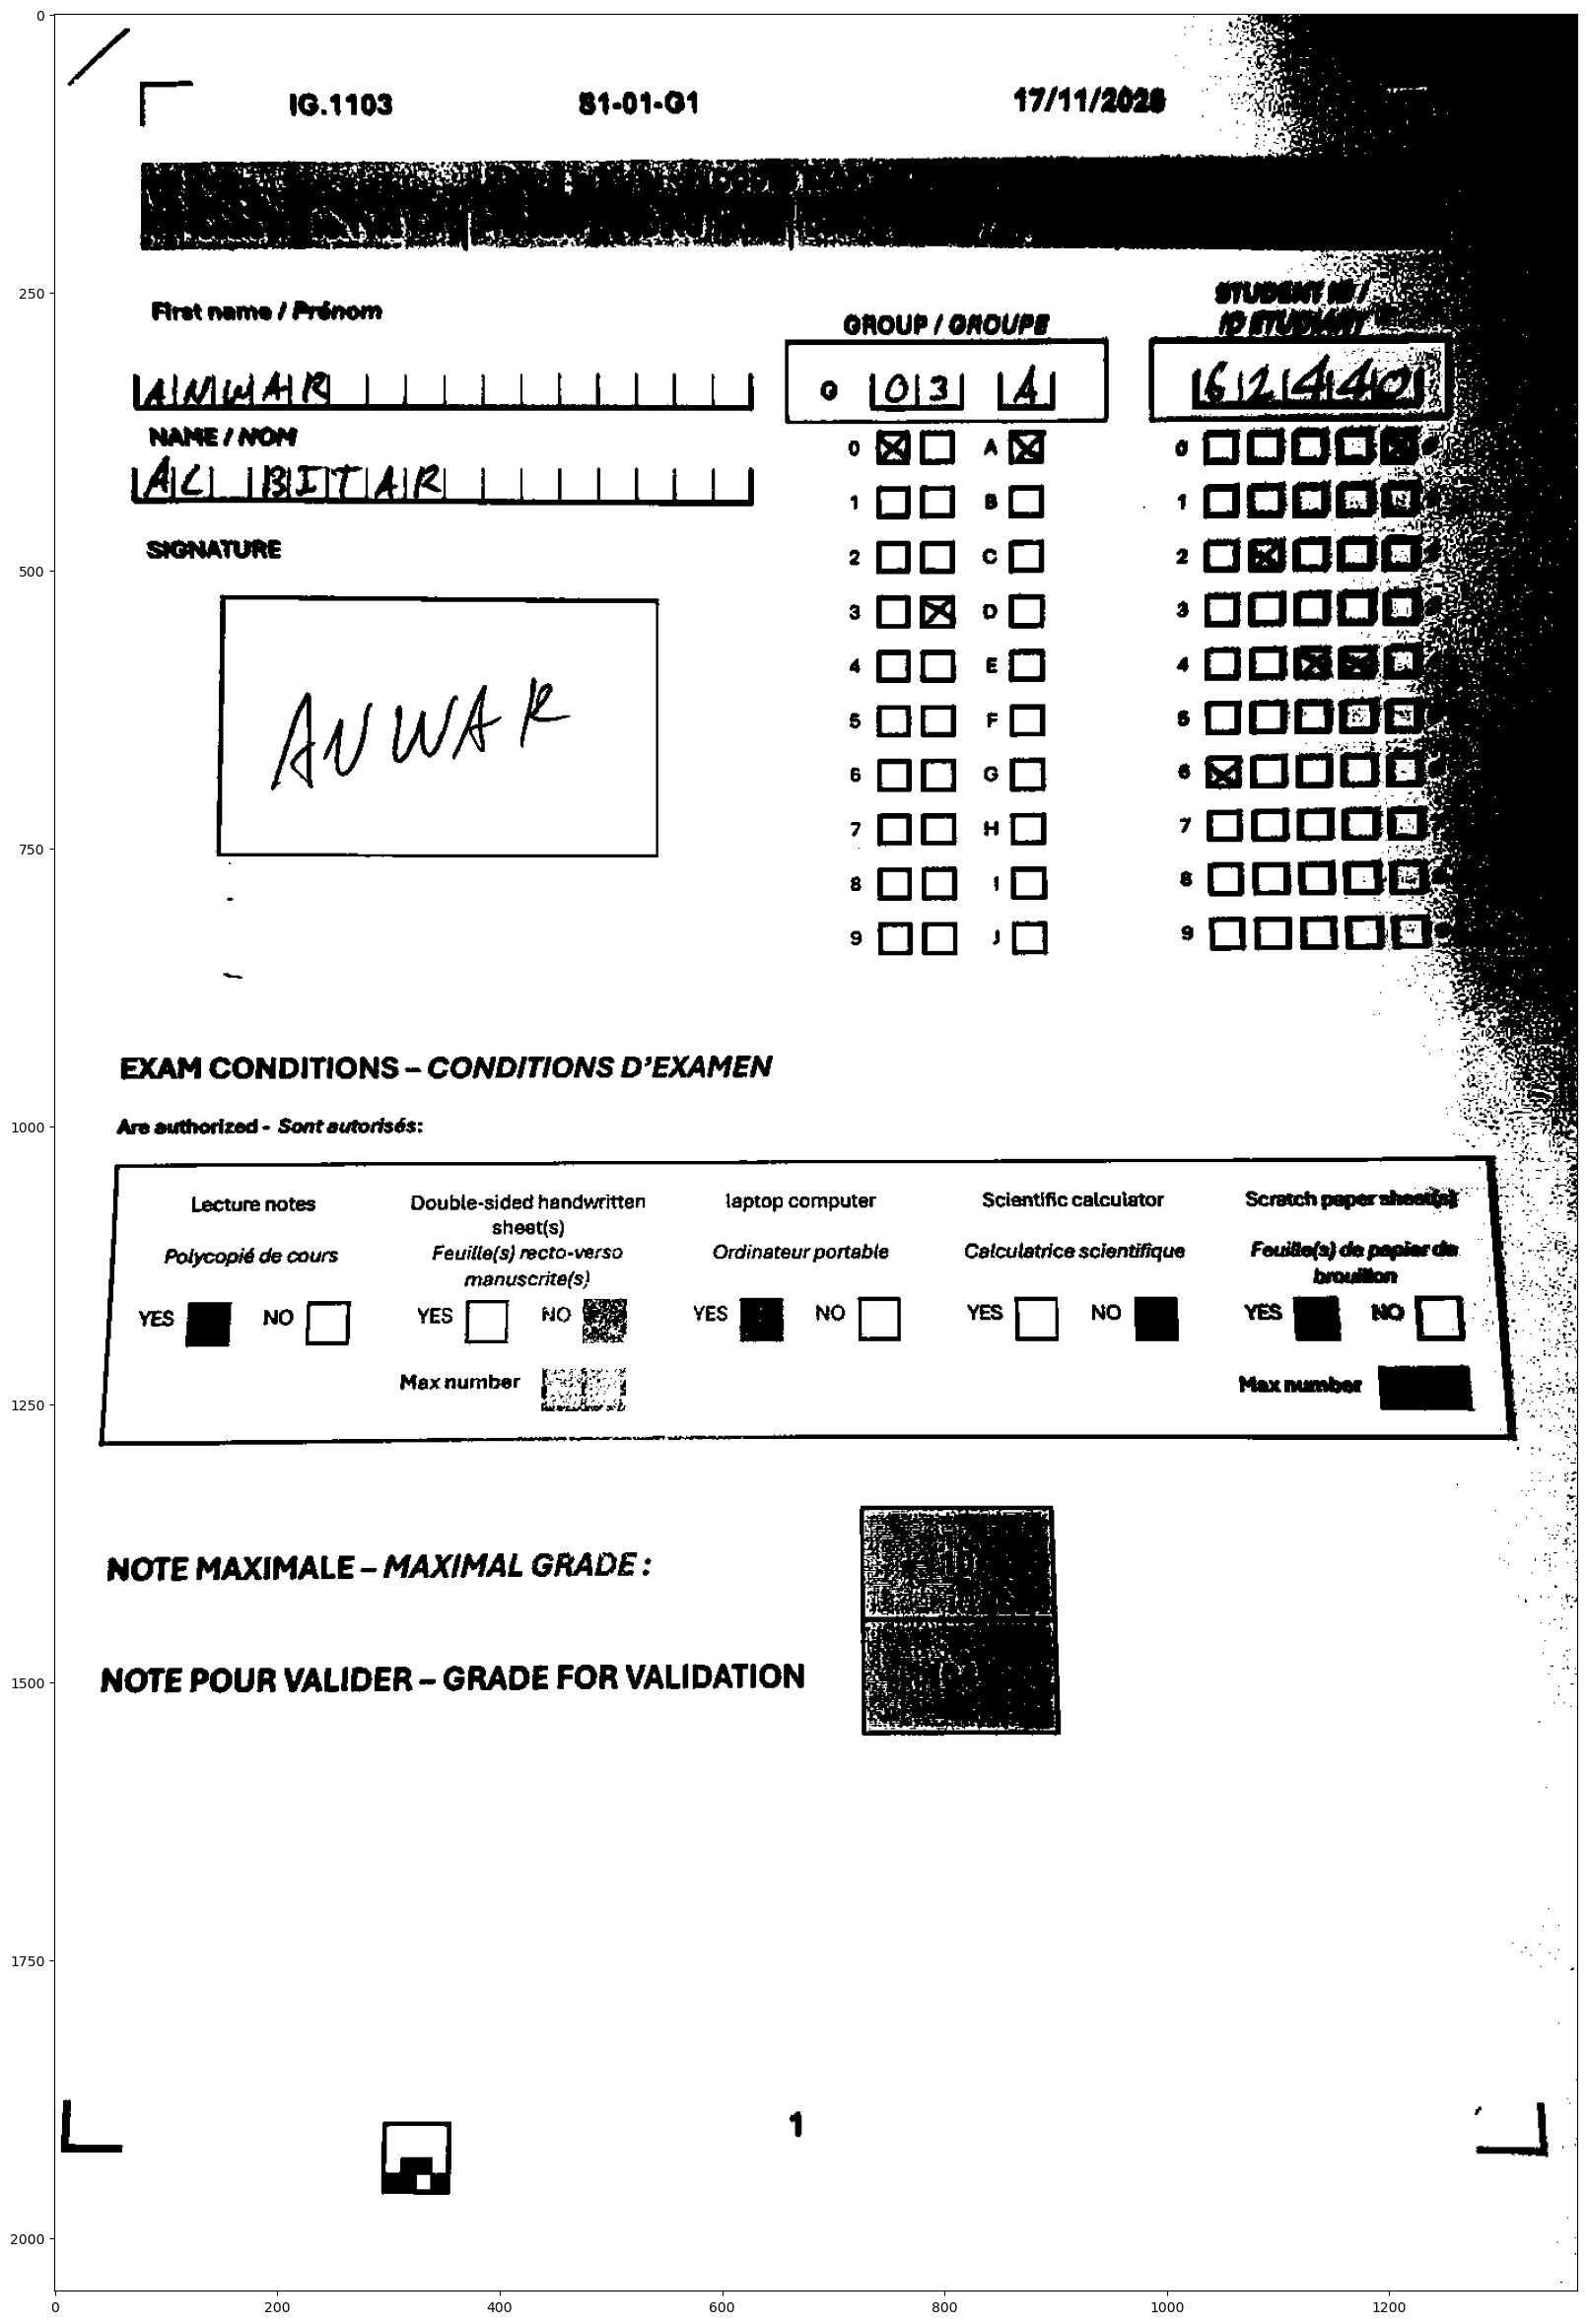

In [5]:
plt.figure(figsize=(30, 30))
plt.imshow(result, cmap='gray')

In [6]:
# --------------------------
# ✅ 1. BINARISATION
# --------------------------
threshold = filters.threshold_otsu(im2)
result = (im2 > threshold)

# --------------------------
# ✅ 2. EXTRACTION BOXES
# --------------------------
boxes = []

for k, size in filtered:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    cx = (min_col + max_col) / 2
    cy = (min_row + max_row) / 2

    boxes.append((k, size, cx, cy,
                  int(min_row), int(min_col),
                  int(max_row), int(max_col)))

# --------------------------
# ✅ 3. TRI + REGROUPEMENT LIGNES
# --------------------------
boxes = sorted(boxes, key=lambda x: (x[3], x[2]))



rows = []

for i in range(0, len(boxes), 8):
    row = boxes[i:i+8]
    row.sort(key=lambda x: x[2])  # sécuriser ordre horizontal
    rows.append(row)


    


# tri interne
for row in rows:
    row.sort(key=lambda x: x[2])

rows.sort(key=lambda r: np.mean([b[3] for b in r]))

# --------------------------
# ✅ 4. MATRICE
# --------------------------
matrice = np.zeros((len(rows), len(rows[0])))

scores_list = []

for i, row in enumerate(rows):
    for j, b in enumerate(row):
        
        k, size, cx, cy, min_row, min_col, max_row, max_col = b
        
        case = result[min_row:max_row, min_col:max_col]

        # ✅ Sobel marche mieux chez toi
        edges = filters.sobel(case)
        score = np.sum(edges)

        scores_list.append((score, i, j))

# --------------------------
# ✅ 5. SEUIL ADAPTÉ
# --------------------------
scores_only = [s for s, _, _ in scores_list]
threshold_score = np.mean(scores_only) + 0.5*np.std(scores_only)

selected = [(s, i, j) for (s, i, j) in scores_list if s > threshold_score]

selected.sort(reverse=True, key=lambda x: x[0])
selected = selected[:8]

# --------------------------
# ✅ 6. REMPLISSAGE MATRICE
# --------------------------
for score, i, j in selected:
    if i < matrice.shape[0] and j < matrice.shape[1]:
        matrice[i, j] = 1

# --------------------------
# ✅ 7. LECTURE
# --------------------------
mat_groupe = matrice[:, :3]
mat_id = matrice[:, 3:]

alphabet = "ABCDEFGHIJ"

groupe = ""
for j in range(mat_groupe.shape[1]):
    idx = np.argmax(mat_groupe[:, j])
    groupe += str(idx) if j < 2 else alphabet[idx]

identifiant = ""
for j in range(mat_id.shape[1]):
    idx = np.argmax(mat_id[:, j])
    identifiant += str(idx)

print("Groupe:", groupe)
print("ID:", identifiant)


Groupe: 03A
ID: 60000
